# Анализ разбиений

In [1]:
%matplotlib inline
from pathlib import Path
import json

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 42
CHUNK_SIZE = 250_000
ROOT = Path("..") if Path("../pyproject.toml").is_file() else Path(".")
SPLIT_ROOT = ROOT / "data" / "splits" / f"seed_{SEED}"
NAMES = {
    "amazon": "Amazon",
    "retailrocket": "Retailrocket",
    "rees46_cosmetics": "REES46 Cosmetics",
    "rees46_electronics": "REES46 Electronics",
}
SPLITS = ["train", "validation", "test"]

required = [SPLIT_ROOT / name / filename for name in NAMES
            for filename in ["train.csv.gz", "validation.csv.gz", "test.csv.gz", "train_items.csv.gz"]]
missing = [str(path) for path in required if not path.is_file()]
if missing:
    raise FileNotFoundError("Сначала выполните dataset_splitting.ipynb. Не найдены:\n" + "\n".join(missing))

plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True,
                     "grid.alpha": 0.2, "font.family": "DejaVu Sans"})
print("Разбиения:", SPLIT_ROOT)

Разбиения: data/splits/seed_42


## 1. Подсчёт наблюдений

Считаем строки пар, а не уникальные рёбра или запросы: повторения пары в разных группах событий учитываются отдельно. Для Amazon `known_user` отсутствует, поскольку метаданные не содержат пользователей.

`known_user=True` означает, что пользователь встречался в train-событиях. Значения флага проверяются явно: строка `"False"` не должна интерпретироваться как истинное значение.

In [2]:
def count_split(path, with_users):
    columns = ["relation"] + (["known_user"] if with_users else [])
    counts = {"rows": 0, "buy": 0, "view": 0, "known_user_buy": 0}
    for chunk in pd.read_csv(path, usecols=columns, dtype="string", chunksize=CHUNK_SIZE):
        if not chunk.relation.isin(["buy", "view"]).all():
            raise ValueError(f"Неизвестный или пустой тип отношения: {path}")
        is_buy = chunk.relation.eq("buy")
        counts["rows"] += len(chunk)
        counts["buy"] += int(is_buy.sum())
        counts["view"] += int(chunk.relation.eq("view").sum())
        if with_users:
            flags = chunk.known_user.str.strip().str.lower()
            if not flags.isin(["true", "false"]).all():
                raise ValueError(f"Некорректный known_user: {path}")
            counts["known_user_buy"] += int((is_buy & flags.eq("true")).sum())
    return counts

stats = {}
item_counts = {}
for dataset in NAMES:
    folder = SPLIT_ROOT / dataset
    stats[dataset] = {split: count_split(folder / f"{split}.csv.gz", dataset != "amazon")
                      for split in SPLITS}
    for split in ["validation", "test"]:
        if stats[dataset][split]["view"]:
            raise ValueError(f"В {dataset}/{split} найдены просмотры; ожидаются только покупки")
    items = pd.read_csv(folder / "train_items.csv.gz", usecols=["item_id"], dtype="string")
    if items.item_id.isna().any() or items.item_id.duplicated().any():
        raise ValueError(f"Пустые или повторные ID в {folder / 'train_items.csv.gz'}")
    item_counts[dataset] = len(items)
    print(f"{NAMES[dataset]}: подсчёт завершён")

Amazon: подсчёт завершён


Retailrocket: подсчёт завершён


REES46 Cosmetics: подсчёт завершён


REES46 Electronics: подсчёт завершён


## 2. Размеры разбиений

Train содержит покупки и просмотры, validation/test — только покупки после фильтрации. `train_items` перечисляет известные товары: для Amazon — из train-пар, для журналов — из train-событий. Последнее не гарантирует наличие обучающих пар для каждого товара.

,Train: buy,Train: view,Validation: buy,Test: buy,Товаров в train_items
Набор,,,,,
Amazon,68568,243871,8195,8243,50540
Retailrocket,5871,1014808,974,758,212915
REES46 Cosmetics,8583649,18409579,1121086,1015086,51338
REES46 Electronics,3453,318580,926,740,50175


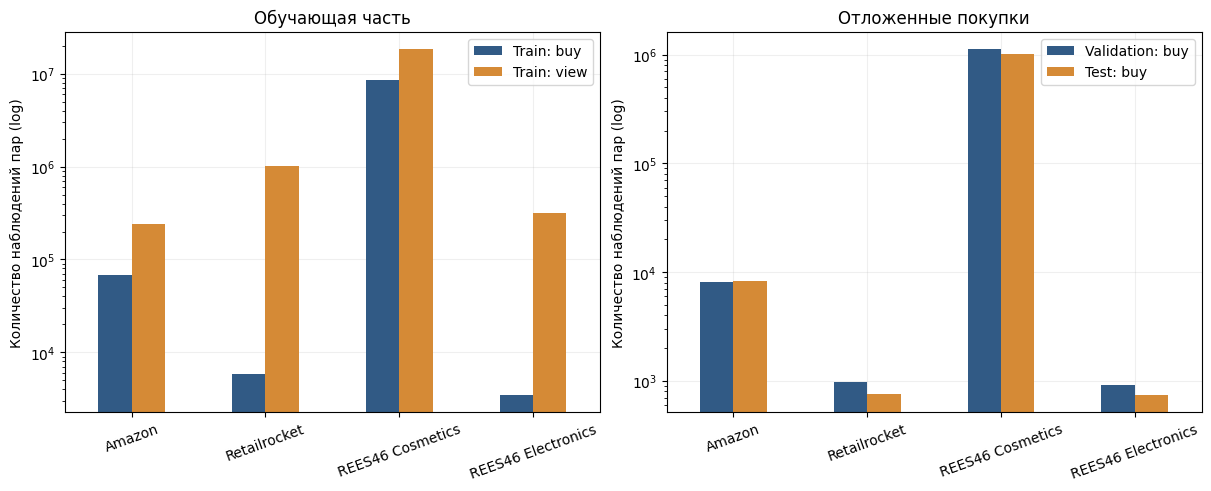

In [3]:
sizes = pd.DataFrame([
    {"Набор": label,
     "Train: buy": stats[key]["train"]["buy"],
     "Train: view": stats[key]["train"]["view"],
     "Validation: buy": stats[key]["validation"]["buy"],
     "Test: buy": stats[key]["test"]["buy"],
     "Товаров в train_items": item_counts[key]}
    for key, label in NAMES.items()
]).set_index("Набор")
display(sizes)

fig_sizes, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")
sizes[["Train: buy", "Train: view"]].plot.bar(ax=axes[0], color=["#315a85", "#d58a36"], rot=20)
sizes[["Validation: buy", "Test: buy"]].plot.bar(ax=axes[1], color=["#315a85", "#d58a36"], rot=20)
for ax, title in zip(axes, ["Обучающая часть", "Отложенные покупки"]):
    ax.set(title=title, xlabel="", ylabel="Количество наблюдений пар (log)")
    ax.set_yscale("log")
    ax.set_axisbelow(True)
plt.show()

## 3. Пары с известными пользователями

В дробях числитель — количество buy-пар с `known_user=True`, знаменатель — все buy-пары соответствующей части. Проценты относятся к наблюдениям пар, а не к уникальным пользователям. Amazon здесь не рассматривается.

Это предварительное покрытие для 4D: дополнительно нужно проверить, что пользователь и товары имеют обучающие пары, необходимые для обучения их факторов.

In [4]:
coverage_rows = []
for key, label in NAMES.items():
    if key == "amazon":
        continue
    row = {"Набор": label}
    for split, title in [("validation", "Validation"), ("test", "Test")]:
        total = stats[key][split]["buy"]
        known = stats[key][split]["known_user_buy"]
        row[f"{title}: известные"] = known
        row[f"{title}: всего"] = total
        row[f"Доля {split}, %"] = 100 * known / total if total else float("nan")
    coverage_rows.append(row)
coverage = pd.DataFrame(coverage_rows).set_index("Набор")
coverage_table = pd.DataFrame(index=coverage.index)
for split, title in [("validation", "Validation"), ("test", "Test")]:
    coverage_table[f"{title}: пары с known_user=True"] = [
        f"{known:,} / {total:,}".replace(",", " ")
        for known, total in zip(coverage[f"{title}: известные"], coverage[f"{title}: всего"])
    ]
    coverage_table[f"Доля {split}, %"] = coverage[f"Доля {split}, %"].round(2)
display(coverage_table)

,Validation: пары с known_user=True,"Доля validation, %",Test: пары с known_user=True,"Доля test, %"
Набор,,,,
Retailrocket,331 / 974,33.98,121 / 758,15.96
REES46 Cosmetics,813 093 / 1 121 086,72.53,549 360 / 1 015 086,54.12
REES46 Electronics,87 / 926,9.40,73 / 740,9.86


## 4. Покрытие тестовых пар

График показывает, какая часть тестовых покупочных пар остаётся после отбора пользователей, встречавшихся в train-событиях. Для сравнения 3D и 4D следует использовать одинаковое подмножество запросов. Пустой тест означает неопределённую долю, а не нулевое покрытие.

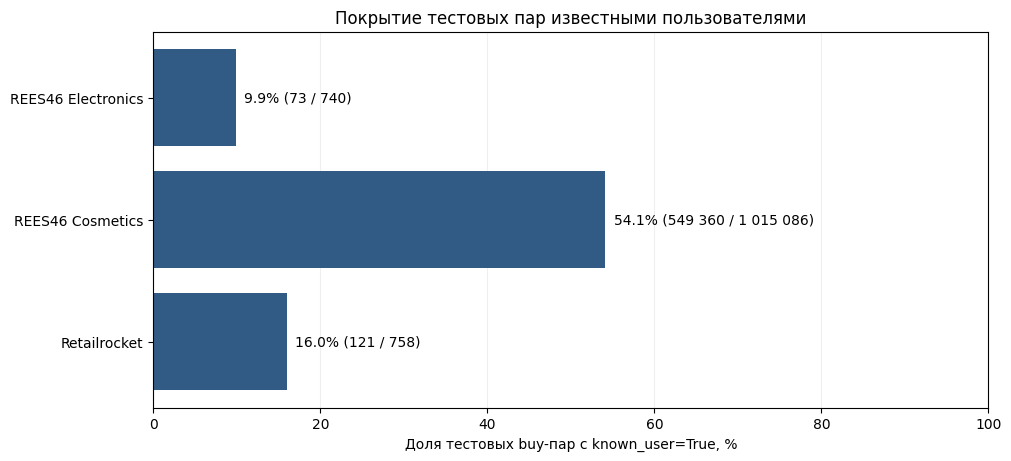

In [5]:
fig_users, ax = plt.subplots(figsize=(10, 4.5), layout="constrained")
shares = coverage["Доля test, %"]
bars = ax.barh(coverage.index, shares, color="#315a85")
ax.set(xlim=(0, 100), xlabel="Доля тестовых buy-пар с known_user=True, %",
       title="Покрытие тестовых пар известными пользователями")
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)
for bar, (name, row) in zip(bars, coverage.iterrows()):
    share = row["Доля test, %"]
    if pd.isna(share):
        ax.text(1, bar.get_y() + bar.get_height() / 2, "Нет тестовых пар", va="center")
        continue
    text = (f"{share:.1f}% ({int(row['Test: известные']):,} / "
            f"{int(row['Test: всего']):,})").replace(",", " ")
    # У правого края размещаем подпись внутри области графика.
    ax.text(share + 1 if share < 65 else share - 1,
            bar.get_y() + bar.get_height() / 2, text,
            ha="left" if share < 65 else "right", va="center")
plt.show()

## 5. Временные границы

Дополнительная таблица из `split_info.json`. `events_removed` — число событий, исключённых при разбиении, включая некорректные события и пересекающие границы группы; это не число удалённых пар. У Amazon временных границ нет.

In [6]:
boundary_rows = []
for key, label in NAMES.items():
    if key == "amazon":
        continue
    path = SPLIT_ROOT / key / "split_info.json"
    metadata = json.loads(path.read_text())
    boundary_rows.append({"Набор": label,
                          "Начало validation, UTC": metadata["validation_start"],
                          "Начало test, UTC": metadata["test_start"],
                          "Исключено событий": metadata["events_removed"]})
boundaries = pd.DataFrame(boundary_rows).set_index("Набор")
display(boundaries)

,"Начало validation, UTC","Начало test, UTC",Исключено событий
Набор,,,
Retailrocket,2015-08-18 04:23:20.445000+00:00,2015-09-02 17:49:14.032000+00:00,305
REES46 Cosmetics,2020-01-31 23:40:01+00:00,2020-02-14 20:06:22+00:00,506570
REES46 Electronics,2021-01-30 10:17:09+00:00,2021-02-13 11:50:32+00:00,15849
